<a href="https://colab.research.google.com/github/nahdaauliya/PCVK_Ganjil_2026/blob/main/praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PRAKTIKUM 2

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1. Tampilkan satu citra bebas menggunakan cv2_imshow() dan plt imshow() tanpa konversi warna apa pun. Mengapa hasilnya berbeda? Buktikan dengan mencetak nilai satu piksel yang sama dari kedua cara pembacaan tersebut.

Hasil berbeda
- cv.imshow() digunakan untuk menampilkan gambar dalam format BGR(Blue Green, Red) yang dihasilkan oleh OpenCV.
- plt.imshow() digunakan untuk menampilkan gambar dalam bentuk format RGB(Red, Green, Blue) yang dihasilkan oleh Matplotlib.

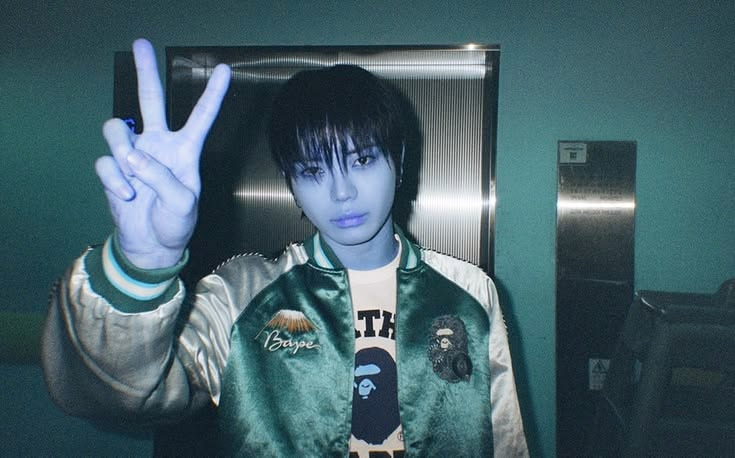

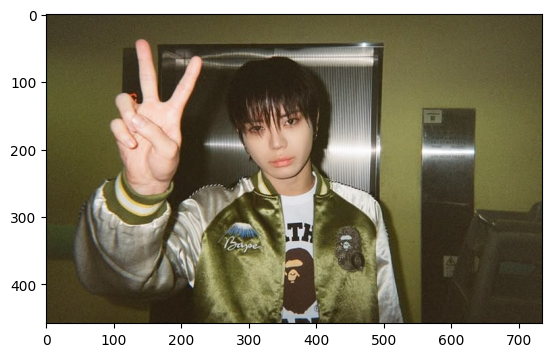

In [5]:
import cv2
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/Ohyul Lngshot.jpg")   # nama file sesua yang diupload
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

cv2_imshow(img2)
plt.imshow(img2)

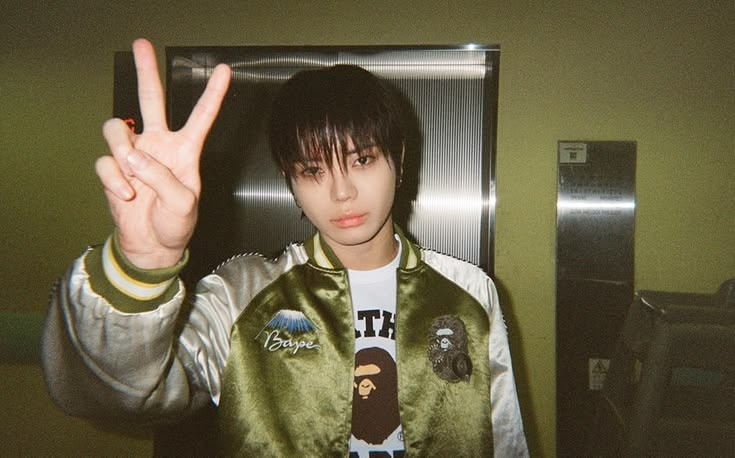

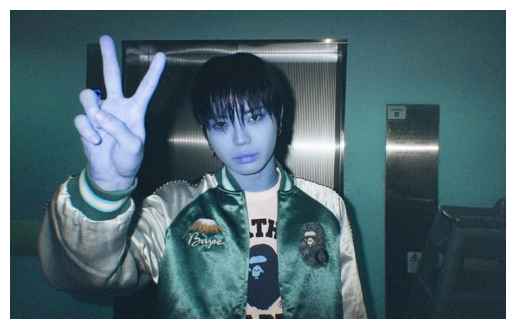

Koordinat piksel: (100, 100)
Nilai piksel: [ 51  93 100]

Menurut OpenCV (BGR):
Blue : 51
Green: 93
Red  : 100

Menurut Matplotlib (RGB):
Red  : 51
Green: 93
Blue : 100


In [4]:
import cv2
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/Ohyul Lngshot.jpg")

cv2_imshow(img)

plt.imshow(img)
plt.axis("off")
plt.show()

x = 100
y = 100

pixel = img[y, x]

print("Koordinat piksel:", (x, y))
print("Nilai piksel:", pixel)

print("\nMenurut OpenCV (BGR):")
print("Blue :", pixel[0])
print("Green:", pixel[1])
print("Red  :", pixel[2])

print("\nMenurut Matplotlib (RGB):")
print("Red  :", pixel[0])
print("Green:", pixel[1])
print("Blue :", pixel[2])

### 2. Buat kanvas hitam berukuran sama dengan tipe data int16 dan int32. Bandingkan dtype, min(), max(), dan nbytes keduanya. Apakah tampilannya berbeda? Apakah ukuran memorinya berbeda? Jelaskan alasannya.

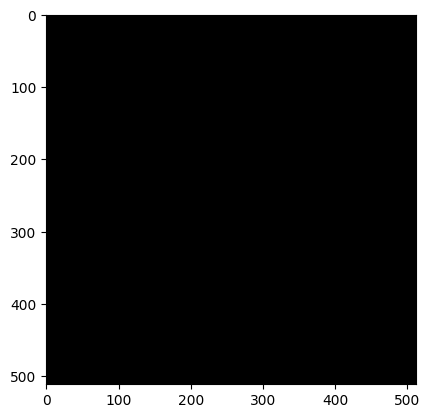

In [9]:
import numpy as np

black_img = np.zeros((512,512,3), dtype=np.int16)

plt.imshow(black_img)

plt.show()

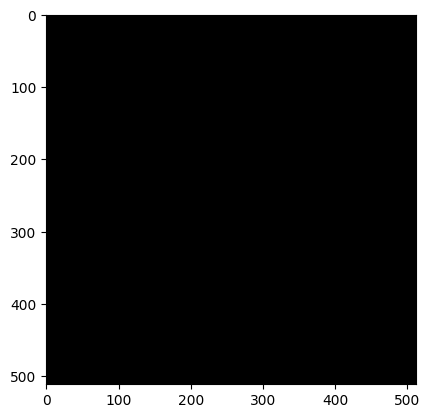

In [11]:
black_img2 = np.zeros((512,512,3), dtype=np.int32)

plt.imshow(black_img2)
plt.show()

### Perbedaan int16 dan int32

**int16**
- dtype: int16
- min(): -32,768
- max(): 32,767
- nbytes: 2 byte

**int32**
- dtype: int32
- min(): -2,147,483,648
- max(): 2,147,483,647
- nbytes: 4 byte

Tampilannya tidak berbeda, namun ukuran memory nya berbeda. Karena int32 memiliki 4 byte, yang dimana dtype ini memiliki rentang nilai yang lebih besar dibandingkan int16, sehingga dapat merepresentasikan nilai integer yang lebih besar.

### 3. Apa kegunaan baris from google.colab.patches import cv2_imshow, dan mengapa cv2.imshow() bawaan OpenCV tidak dapat dipakai di Google Colab?

jawaban:
- Kegunaan from google.colab.patches import cv2_imshow adalah untuk mengimporfungsi cv_imshow yang disediakan oleh Google Colab untuk menampilkan gambar. Gambar tersebut akan ditampilkan langsung di output cell Google Colab.

- cv2.imshow() bawaan OpenCv dirancang untuk menampilkan gambar melalui window GUI pada komputer lokal. Sementara Google Colab berjalan di lingkungan cloud dan notebooknya menggunakan browser. Sehingga jika dijalankan, output akan memunculkan error. Oleh karena itu Google Colab menyediakan alternatif untuk menampilkan gambar di output notebook.

### 4. Citra yang dibaca dengan skimage.io.imread() ditampilkan berdampingan dengan hasil cv2.cvtColor(img, cv2.COLOR_BGR2RGB) atas citra yang sama. Manakah yang menampilkan warna sebenarnya, dan manakah yang kanalnya tertukar? Buktikan dengan nilai piksel, bukan dengan pengamatan visual saja.

skimage.io.imread() membaca citra alam urutan kanal RGB, sehingga ketika ditampilkan menggunakan plt.imshow(), warna ditampilkan dengan urutan kanal yang benar

Sementara, cv2.imread() membaca citra dalam urutan BGR. Oleh karena itu, apabila hasil cv2.imread() langsung ditampilkan menggunakan fungsi yang mengharapkan RGB, kanal red dan blue akan tertukar. Namun, untuk memperbaikinya, kita bisa menggunakan cv2.cvtColor(img, cv2.COLOR_BGR2RGB). Setelah dikonversi menggunakan kode tersebut, image memiliki urutan kanal RGB, sehingga hasilnya seharusnya sama dengan citra yang dibaca menggunakan skimage.io.imread()

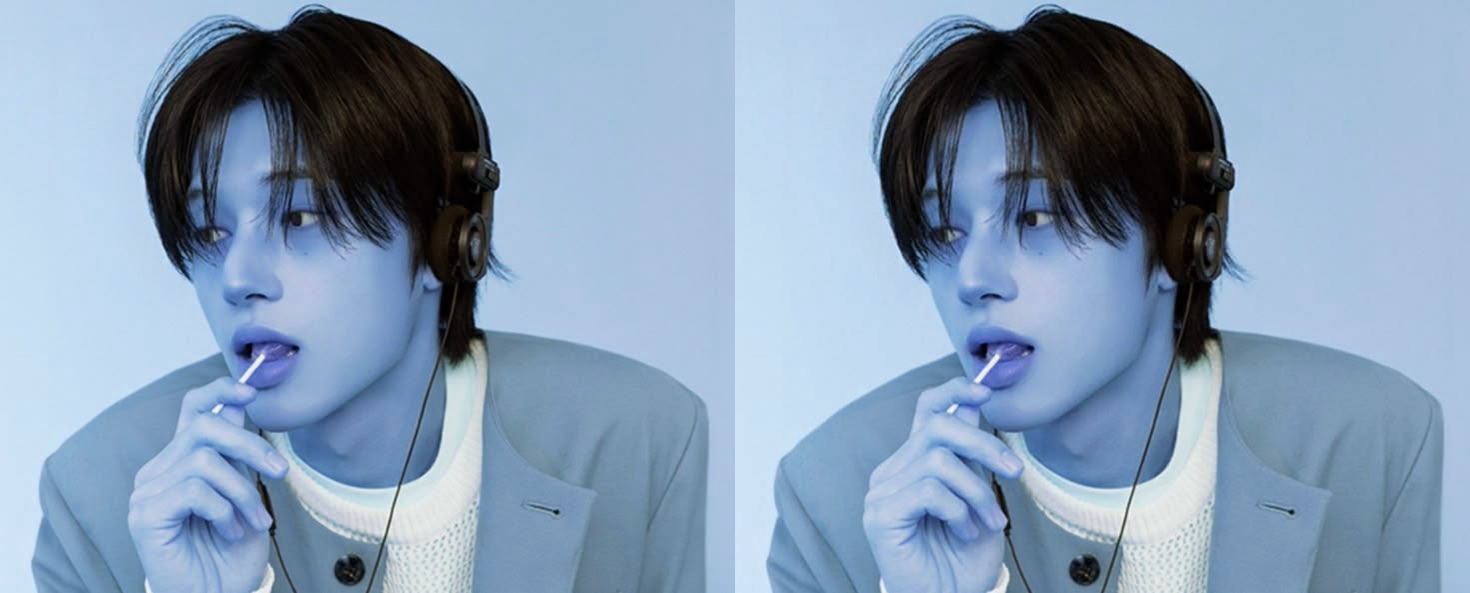

Nilai piksel pada koordinat (x=100, y=100):
Skimage RGB : [236 212 186]
OpenCV RGB  : [236 212 186]


In [18]:
from skimage import io
from skimage import transform

img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/wooyoung.jpg")

image = io.imread("/content/drive/MyDrive/PCVK/Gambar/wooyoung.jpg")
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
final_frame = cv2.hconcat((image, img2))
cv2_imshow(final_frame)

x = 100
y = 100

# Menampilkan nilai piksel
print("Nilai piksel pada koordinat (x={}, y={}):".format(x, y))

print("Skimage RGB :", image[y, x])
print("OpenCV RGB  :", img2[y, x])


### 5. Setelah citra ditampilkan dengan figsize yang jauh lebih besar, apakah nilai img.shape ikut berubah? Jelaskan perbedaan antara mengubah ukuran citra dan mengubah ukuran tampilan.

Tidak, nilai img.shape tidak akan berubah ketika citra ditampilkan dengan figsize yang lebih besar. Hal tersebut karena figsize hanya mengatur ukuran tampilan atau figure pada saat citra ditampilkan, bukan mengubah ukuran citra sebenarnya. Jika ingin merubah ukuran citra, dapat dilakukan dengan proses cv.resize(), yang dapat merubah jumlah piksel dan nilai img.shape.

(593, 735, 3)


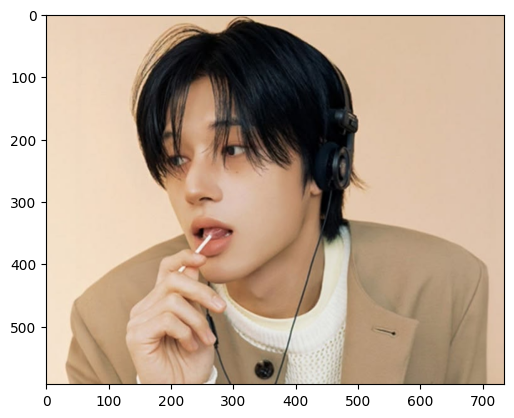

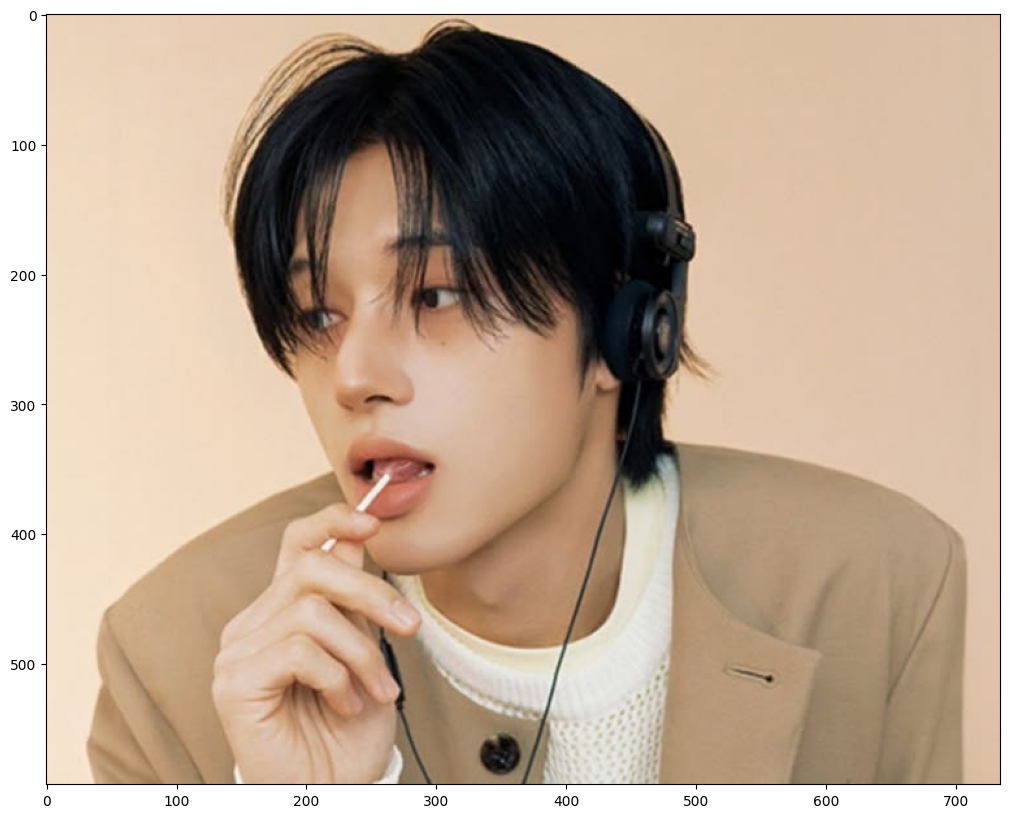

(593, 735, 3)


In [24]:
img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/wooyoung.jpg")
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(img2.shape)
plt.imshow(img2)
plt.show()

img3 = img2.copy()
plt.figure(figsize=(15, 10))
plt.imshow(img3)
plt.show()

print(img3.shape)

(593, 735, 3)


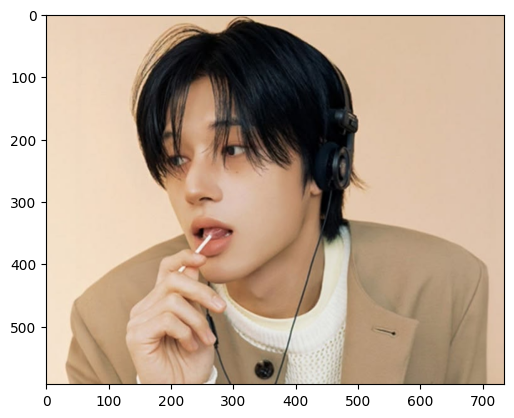

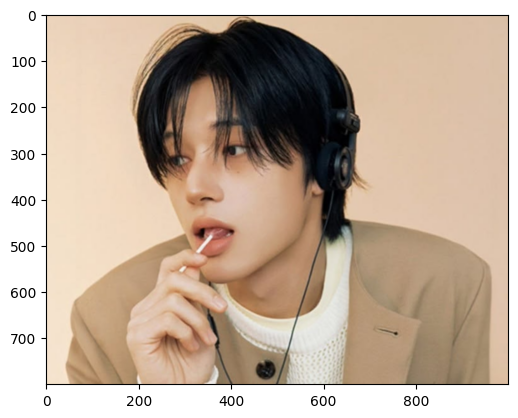

(800, 1000, 3)


In [25]:
img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/wooyoung.jpg")
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(img2.shape)
plt.imshow(img2)
plt.show()

img3 = img2.copy()
img_resized = cv2.resize(img3, (1000, 800))
plt.imshow(img_resized)
plt.show()

print(img_resized.shape)

## TUGAS PRAKTIKUM - Penerapan

### 1. Tampilkan citra hanya pada kombinasi kanal Merah-Biru dan kanal Hijau-Biru saja, dengan kanal yang tidak dipakai dinolkan. Susun keduanya berdampingan dalam satu figure yang diberi judul.

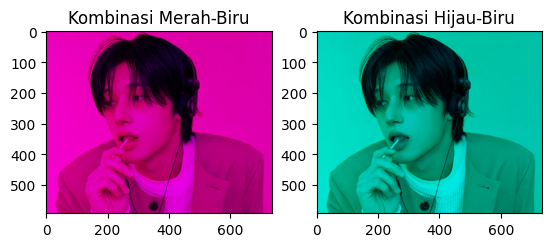

In [28]:
img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/wooyoung.jpg")
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

img_mb = img2.copy()
img_mb[:,:,1] = 0

plt.subplot(1,2,1)
plt.imshow(img_mb)
plt.title('Kombinasi Merah-Biru')

img_hb = img2.copy()
img_hb[:, :, 0] = 0

plt.subplot(1,2,2)
plt.imshow(img_hb)
plt.title('Kombinasi Hijau-Biru')
plt.show()



### 2. Tampilkan citra dalam tiga bentuk pencerminan: vertikal, horizontal, dan keduanya, dalam satu figure berisi tiga subplot yang masing-masing diberi label.

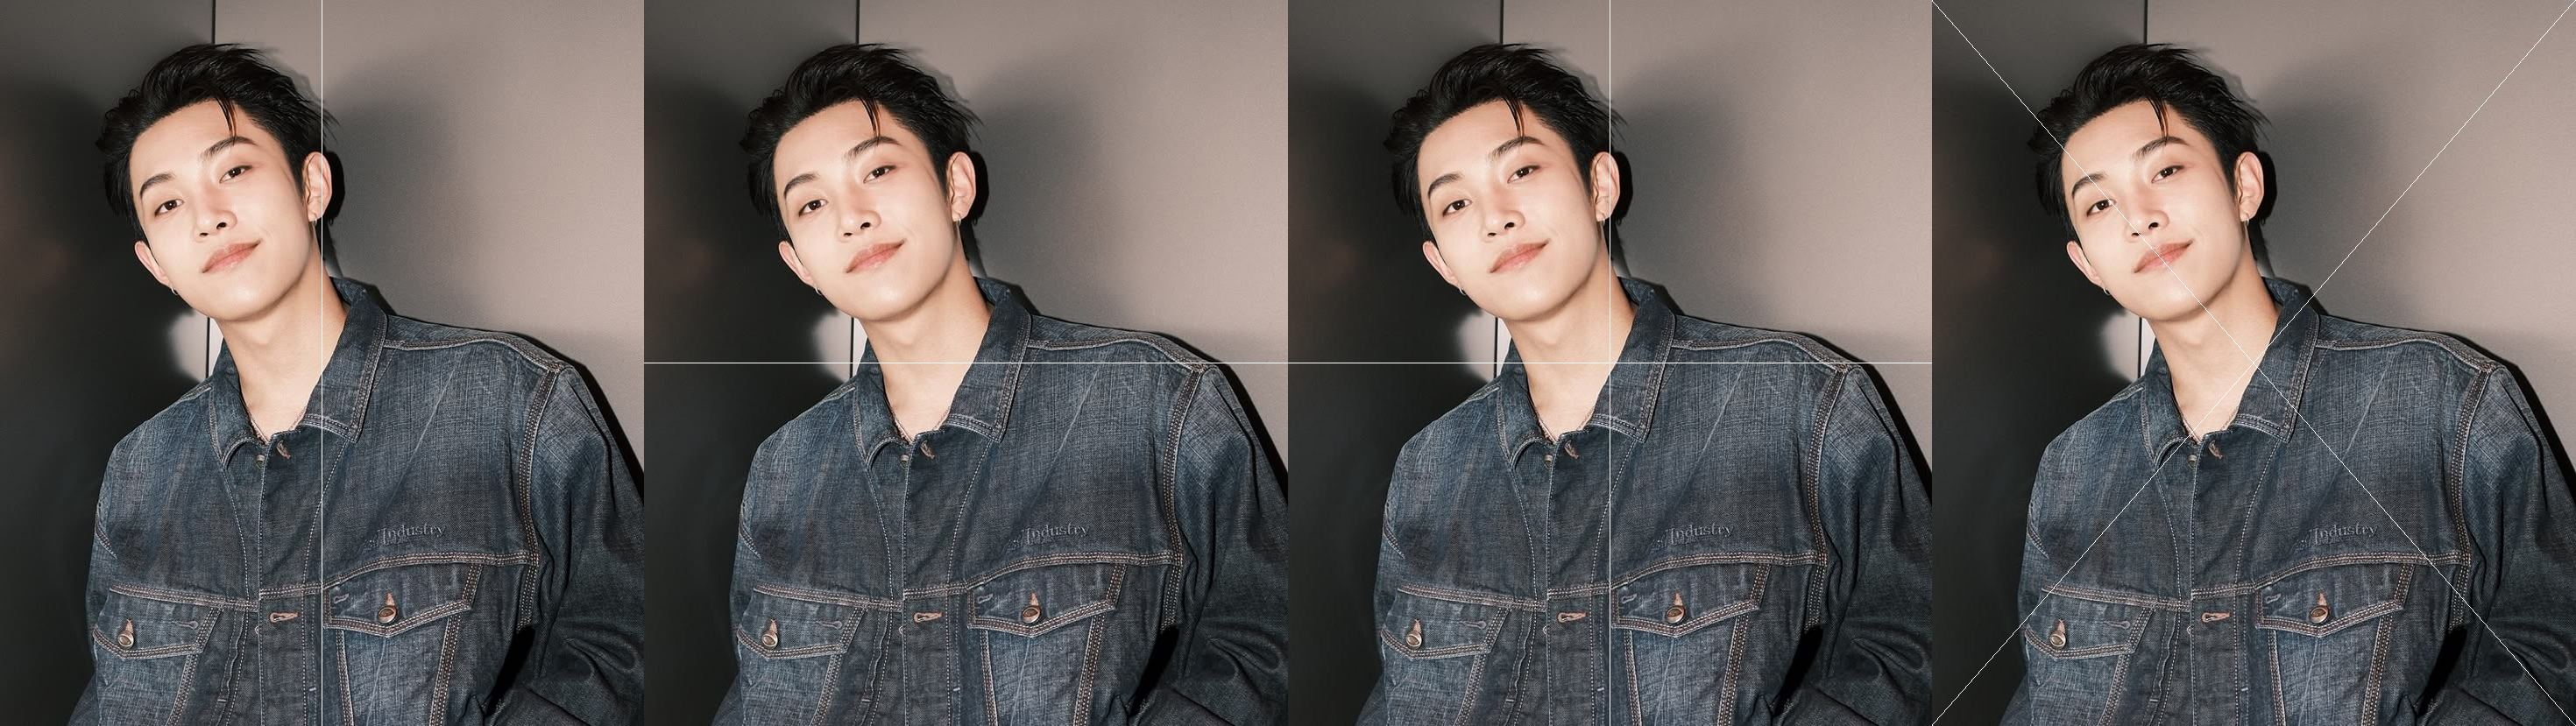

In [32]:
img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/Ryul __ LNGSHOT.jpg")
tinggi = img2.shape[0]
lebar = img2.shape[1]

img3 = img.copy()
img4 = img.copy()
img5 = img.copy()
img6 = img.copy()

for y in range (tinggi):
  img3[y, int((lebar)/2)] =[255,255,255]

for y in range(lebar):
  img4[int((tinggi)/2), y] =[255,255,255]

for y in range(tinggi):
  img5[y, int((lebar)/2)] =[255,255,255]

for y in range(lebar):
  img5[int((tinggi)/2), y] =[255,255,255]

for y in range(tinggi):
  x = int(y*lebar/tinggi)
  img6[y,x] = [255,255,255]

for y in range(tinggi):
  x = int(lebar - 1 - (y*lebar/tinggi))
  img6[y,x] = [255,255,255]

final_frame =cv2.hconcat((img3, img4, img5, img6))
cv2_imshow(final_frame)


### 3. Gambarkan sebuah rectangle dan sebuah circle pada bagian wajah / badan dari foto aktivitas Anda sendiri (bukan pasfoto), lalu tambahkan teks berisi nama Anda dengan pilihan font, ukuran, dan warna yang Anda tentukan sendiri.

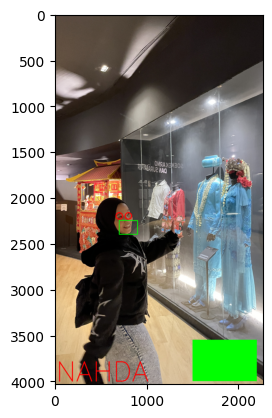

In [33]:
img = cv2.imread("/content/drive/MyDrive/PCVK/Gambar/NADABEN.JPG")
img2 = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

cv2.rectangle(img2, pt1=(700, 2400), pt2=(900, 2250), color=(0, 255, 0), thickness=8)
cv2.circle(img2, center=(700,2200), radius=35, color=(255,0,0), thickness=10)
cv2.circle(img2, center=(800,2200), radius=35, color=(255,0,0), thickness=10)

font=cv2.FONT_HERSHEY_SIMPLEX

cv2.rectangle(img2, pt1=(1500, 3550), pt2=(2200, 4000), color=(0, 255, 0), thickness=-1)
cv2.putText(img2, text='NAHDA', org=(10,4000), fontFace=font, fontScale=10, color=(255,0,0), thickness=10, lineType=cv2.LINE_AA)
plt.imshow(img2)